# Import Library

In [20]:
import json
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Configuration Directory

In [21]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "sampled"
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"

SPLIT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)
print("Split directory:", SPLIT_DIR)

Project root: d:\SMT 5\Deep Learning\EarlySketch
Dataset directory: d:\SMT 5\Deep Learning\EarlySketch\data\sampled
Split directory: d:\SMT 5\Deep Learning\EarlySketch\data\splits


# Load Dataset

In [22]:
def load_ndjson(file_path):
    records = []
    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:
            if not line.strip():
                continue
            try:
                record = json.loads(line)
                records.append(record)
            except json.JSONDecodeError:
                continue
    return records

In [23]:
dataset_files = sorted(DATA_DIR.glob("*.ndjson"))
all_records = []
for file_path in dataset_files:
    category = file_path.stem
    records = load_ndjson(file_path)
    for record in records:
        all_records.append({
            "drawing_id": f"{category}_{record.get('key_id')}",
            "key_id": record.get("key_id"),
            "category": category,
            "word": record.get("word"),
            "recognized": record.get("recognized"),
            "drawing": record.get("drawing")
        })

print("Total original drawings:", len(all_records))

Total original drawings: 5000


# Dataset Validation

In [24]:
def is_valid_drawing(drawing):
    if not isinstance(drawing, list) or len(drawing) == 0:
        return False
    for stroke in drawing:
        if not isinstance(stroke, (list, tuple)):
            return False
        if len(stroke) < 2:
            return False
        x_coords = stroke[0]
        y_coords = stroke[1]
        if not isinstance(x_coords, list):
            return False
        if not isinstance(y_coords, list):
            return False
        if len(x_coords) == 0 or len(x_coords) != len(y_coords):
            return False
        try:
            x = np.asarray(x_coords, dtype=float)
            y = np.asarray(y_coords, dtype=float)
            if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
                return False
        except (ValueError, TypeError):
            return False

    return True

In [25]:
for record in all_records:

    record["is_valid"] = is_valid_drawing(
        record["drawing"]
    )

df = pd.DataFrame(all_records)

print("Total records:", len(df))
print("Valid drawings:", df["is_valid"].sum())
print("Invalid drawings:", (~df["is_valid"]).sum())

Total records: 5000
Valid drawings: 5000
Invalid drawings: 0


# Prepare Metadata

In [26]:
valid_df = df[df["is_valid"]].copy()

metadata_df = valid_df[
    [
        "drawing_id",
        "key_id",
        "category",
        "recognized"
    ]
].copy()

metadata_df = metadata_df.reset_index(drop=True)
metadata_df.head()

,drawing_id,key_id,category,recognized
0,airplane_5290311376961536,5290311376961536,airplane,True
1,airplane_4587020284329984,4587020284329984,airplane,True
2,airplane_4703562825203712,4703562825203712,airplane,True
3,airplane_5442522853670912,5442522853670912,airplane,True
4,airplane_5401917024894976,5401917024894976,airplane,True


# Splitting data using stratified

In [27]:
train_df, temp_df = train_test_split(
    metadata_df,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=metadata_df["category"]
)
validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temp_df["category"]
)

print("Train:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))

Train: 3500
Validation: 750
Test: 750


# Check Data Leakage

In [28]:
train_ids = set(train_df["drawing_id"])
validation_ids = set(validation_df["drawing_id"])
test_ids = set(test_df["drawing_id"])

print("Train ∩ Validation:", len(train_ids & validation_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(validation_ids & test_ids))

assert len(train_ids & validation_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(validation_ids & test_ids) == 0

print("No data leakage detected!")

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0
No data leakage detected!


# Analyze Distribution

,Train,Validation,Test
category,,,
airplane,350,75,75
bicycle,350,75,75
bird,350,75,75
car,350,75,75
cat,350,75,75
dog,350,75,75
fish,350,75,75
flower,350,75,75
house,350,75,75


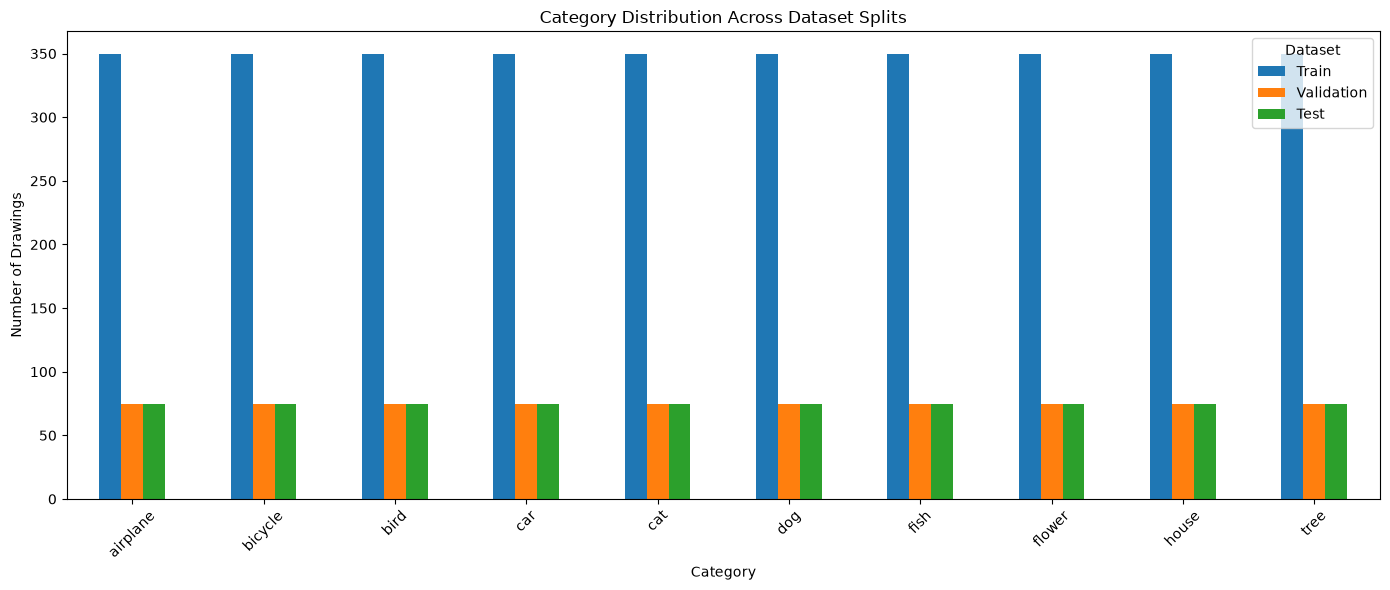

In [30]:
distribution = pd.DataFrame({
    "Train": train_df["category"].value_counts(),
    "Validation": validation_df["category"].value_counts(),
    "Test": test_df["category"].value_counts()
}).fillna(0).astype(int)

display(distribution)


distribution.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Category Distribution Across Dataset Splits")
plt.xlabel("Category")
plt.ylabel("Number of Drawings")
plt.xticks(rotation=45)
plt.legend(title="Dataset")
plt.tight_layout()
plt.savefig(
    REPORT_DIR / "dataset_split_distribution.png",
    dpi=300
)

plt.show()

# Save splitting data

In [31]:
train_df.to_csv(
    SPLIT_DIR / "train.csv",
    index=False
)
validation_df.to_csv(
    SPLIT_DIR / "validation.csv",
    index=False
)
test_df.to_csv(
    SPLIT_DIR / "test.csv",
    index=False
)

print("Dataset splitting completed!")

Dataset splitting completed!
